# Resume Screening: Model Training

Trains classifiers that map resume text to one of 25 job categories and saves the artifacts used by `app.py`.

**Data:** [Resume Dataset (Kaggle)](https://www.kaggle.com/datasets/gauravduttakiit/resume-dataset), file `UpdatedResumeDataSet.csv` with columns `Category` and `Resume`. Place it next to this notebook.

In [1]:
import re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import classification_report, accuracy_score
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 1. Load and explore

(962, 2)
Categories: 25


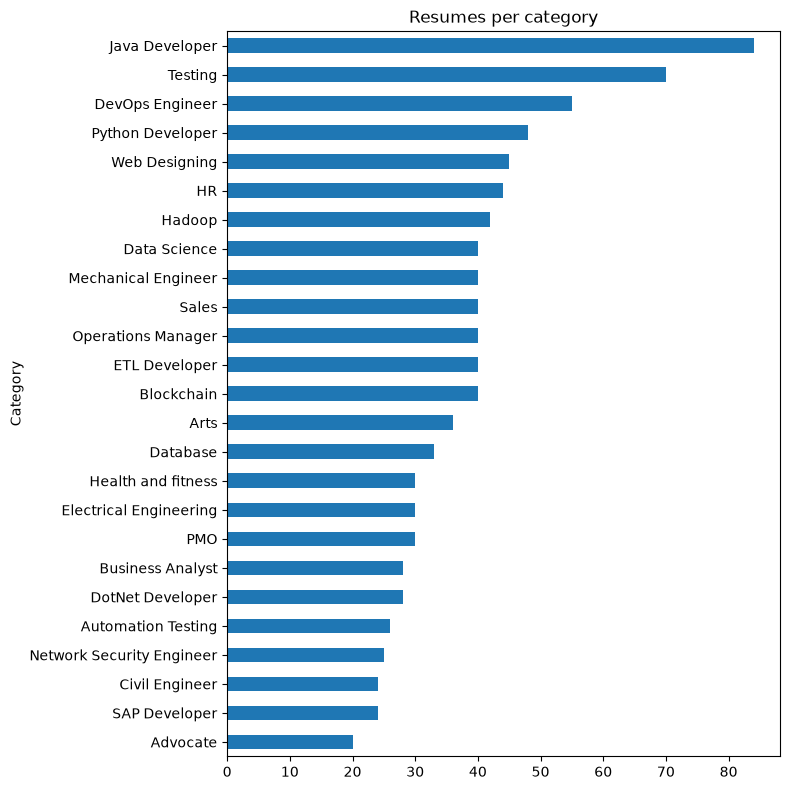

In [2]:
df = pd.read_csv("UpdatedResumeDataSet.csv")
print(df.shape)
print("Categories:", df["Category"].nunique())
df["Category"].value_counts().plot.barh(figsize=(8, 8), title="Resumes per category")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## 2. Data quality check: duplicates

This dataset is known to contain many repeated resumes. If the same resume lands in both the training and the test fold, accuracy is inflated, so we measure it before modelling.

In [3]:
n_total = len(df)
n_unique = df["Resume"].nunique()
print(f"Total rows: {n_total} | unique resumes: {n_unique} | duplicates: {n_total - n_unique} ({(n_total-n_unique)/n_total:.0%})")
df_unique = df.drop_duplicates(subset="Resume").reset_index(drop=True)
print("Unique resumes per category (min / max):", df_unique["Category"].value_counts().min(), "/", df_unique["Category"].value_counts().max())

Total rows: 962 | unique resumes: 166 | duplicates: 796 (83%)
Unique resumes per category (min / max): 3 / 13


## 3. Text cleaning

In [4]:
def clean_text(text):
    text = re.sub(r"http\S+\s*", " ", str(text))          # URLs
    text = re.sub(r"\S+@\S+", " ", text)                   # emails
    text = re.sub(r"\+?\d[\d\s\-()]{7,}\d", " ", text)       # phone numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)                # digits & symbols
    return re.sub(r"\s+", " ", text).lower().strip()

df["clean"] = df["Resume"].apply(clean_text)
df_unique["clean"] = df_unique["Resume"].apply(clean_text)
df["clean"].iloc[0][:300]

'skills programming languages python pandas numpy scipy scikit learn matplotlib sql java javascript jquery machine learning regression svm na ve bayes knn random forest decision trees boosting techniques cluster analysis word embedding sentiment analysis natural language processing dimensionality red'

## 4. Models

In [5]:
def make_models():
    lr  = LogisticRegression(max_iter=2000)
    rf  = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
    xgb = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                        eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1)
    vote = VotingClassifier([("lr", lr), ("rf", rf), ("xgb", xgb)], voting="soft")
    return {"Logistic Regression": lr, "Random Forest": rf, "XGBoost": xgb, "Voting": vote}

from sklearn.pipeline import make_pipeline

def evaluate(data, label):
    # TF-IDF is fitted inside each fold (pipeline) so no information leaks from test folds
    enc = LabelEncoder().fit(data["Category"])
    y = enc.transform(data["Category"])
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for name, model in make_models().items():
        pipe = make_pipeline(TfidfVectorizer(stop_words="english", sublinear_tf=True), model)
        s = cross_val_score(pipe, data["clean"], y, cv=cv, scoring="accuracy", n_jobs=1)
        rows.append({"Data": label, "Model": name, "Mean accuracy": s.mean(), "Std": s.std()})
        print(f"{label:>18} | {name:<20} {s.mean():.4f} ± {s.std():.4f}")
    return pd.DataFrame(rows)

## 5. Stratified 5-fold cross-validation: all rows vs. duplicates removed

In [6]:
res_all = evaluate(df, "All rows")
res_unique = evaluate(df_unique, "Duplicates removed")
results = pd.concat([res_all, res_unique])
results.pivot(index="Model", columns="Data", values="Mean accuracy").round(4)

          All rows | Logistic Regression  0.9907 ± 0.0069


          All rows | Random Forest        0.9948 ± 0.0033


          All rows | XGBoost              0.9979 ± 0.0026


          All rows | Voting               0.9958 ± 0.0039


Duplicates removed | Logistic Regression  0.4159 ± 0.0418


Duplicates removed | Random Forest        0.7535 ± 0.0779


Duplicates removed | XGBoost              0.8615 ± 0.0239


Duplicates removed | Voting               0.8854 ± 0.0524


Data,All rows,Duplicates removed
Model,,
Logistic Regression,0.9907,0.4159
Random Forest,0.9948,0.7535
Voting,0.9958,0.8854
XGBoost,0.9979,0.8615


The *duplicates removed* column is the honest estimate of how the model performs on resumes it has never seen.

## 6. Hold-out report on unique resumes

In [7]:
enc = LabelEncoder().fit(df_unique["Category"])
y = enc.transform(df_unique["Category"])
Xtr, Xte, ytr, yte = train_test_split(df_unique["clean"], y, test_size=0.2,
                                      stratify=y, random_state=RANDOM_STATE)
tfidf = TfidfVectorizer(stop_words="english", sublinear_tf=True).fit(Xtr)
xgb = make_models()["XGBoost"].fit(tfidf.transform(Xtr), ytr)
pred = xgb.predict(tfidf.transform(Xte))
print("Hold-out accuracy:", round(accuracy_score(yte, pred), 4))
print(classification_report(yte, pred, labels=range(len(enc.classes_)),
                            target_names=enc.classes_, zero_division=0))

Hold-out accuracy: 0.7647
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         2
                     Arts       1.00      1.00      1.00         1
       Automation Testing       0.50      1.00      0.67         1
               Blockchain       1.00      1.00      1.00         1
         Business Analyst       0.50      1.00      0.67         1
           Civil Engineer       1.00      1.00      1.00         1
             Data Science       1.00      0.50      0.67         2
                 Database       0.67      1.00      0.80         2
          DevOps Engineer       0.00      0.00      0.00         1
         DotNet Developer       1.00      1.00      1.00         2
            ETL Developer       1.00      1.00      1.00         1
   Electrical Engineering       0.50      1.00      0.67         1
                       HR       1.00      1.00      1.00         2
                   Hadoop       1.0